# 02. Silver Layer – Data Exploration & Transformation

## Objective
Explore, assess, and transform ERA5-Land data
for the Mekong Delta drought prediction project.

## Input
- Bronze ERA5-Land NetCDF
- GADM Vietnam administrative boundaries

## Output
- Mekong Delta spatial boundary
- Clipped ERA5-Land dataset
- Quality assessment report
- Silver analytical dataset

In [32]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import regionmask
import json
import matplotlib.pyplot as plt

Project configuration

In [2]:
PROJECT_DIR = Path.cwd().parent

# Input
BRONZE_FILE = (
    PROJECT_DIR
    / "data/bronze/era5_land/era5_land_monthly_2000_2025.nc"
)

GADM_FILE = (
    PROJECT_DIR
    / "data/raw/gadm41_VNM.json"
)

# Output
SILVER_DIR = PROJECT_DIR / "data/silver"

BOUNDARY_DIR = SILVER_DIR / "boundaries"
ERA5_DIR = SILVER_DIR / "era5_land"

BOUNDARY_FILE = (
    BOUNDARY_DIR / "mekong_delta_boundary.geojson"
)

CLIPPED_FILE = (
    ERA5_DIR / "era5_land_mekong_delta_2000_2025.nc"
)

PARQUET_FILE = (
    ERA5_DIR / "era5_land_mekong_delta_2000_2025.parquet"
)

QUALITY_REPORT = (
    ERA5_DIR / "quality_report.csv"
)

# Create directories
BOUNDARY_DIR.mkdir(parents=True, exist_ok=True)
ERA5_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Bronze file exists:", BRONZE_FILE.exists())
print("GADM file exists:", GADM_FILE.exists())
print("Silver directory:", SILVER_DIR)

Project: /home/trang/Drought_prediction
Bronze file exists: True
GADM file exists: True
Silver directory: /home/trang/Drought_prediction/data/silver


### Section 2 – Data Exploration

Load Bronze dataset

In [3]:
ds = xr.open_dataset(BRONZE_FILE)

print("Dataset loaded successfully!")
print(ds)

Dataset loaded successfully!
<xarray.Dataset> Size: 12MB
Dimensions:     (valid_time: 312, latitude: 32, longitude: 38)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 2kB 2000-01-01 ... 2025-12-01
    expver      (valid_time) <U4 5kB ...
  * latitude    (latitude) float64 256B 11.1 11.0 10.9 10.8 ... 8.3 8.2 8.1 8.0
  * longitude   (longitude) float64 304B 103.3 103.4 103.5 ... 106.8 106.9 107.0
    number      int64 8B ...
Data variables:
    d2m         (valid_time, latitude, longitude) float32 2MB ...
    t2m         (valid_time, latitude, longitude) float32 2MB ...
    swvl1       (valid_time, latitude, longitude) float32 2MB ...
    swvl2       (valid_time, latitude, longitude) float32 2MB ...
    swvl3       (valid_time, latitude, longitude) float32 2MB ...
    swvl4       (valid_time, latitude, longitude) float32 2MB ...
    pev         (valid_time, latitude, longitude) float32 2MB ...
    tp          (valid_time, latitude, longitude) float32 2MB ...
Attributes:
    GR

Explore dataset structure

In [4]:
print("=== DATASET OVERVIEW ===")

print("Dimensions:")
print(ds.sizes)

print("\nCoordinates:")
print(list(ds.coords))

print("\nData variables:")
print(list(ds.data_vars))

print("\nTime range:")
print("Start:", pd.Timestamp(ds.valid_time.min().values))
print("End:", pd.Timestamp(ds.valid_time.max().values))

print("\nSpatial extent:")
print(
    "Latitude:",
    float(ds.latitude.min()),
    "to",
    float(ds.latitude.max())
)

print(
    "Longitude:",
    float(ds.longitude.min()),
    "to",
    float(ds.longitude.max())
)

=== DATASET OVERVIEW ===
Dimensions:
Frozen({'valid_time': 312, 'latitude': 32, 'longitude': 38})

Coordinates:
['number', 'valid_time', 'latitude', 'longitude', 'expver']

Data variables:
['d2m', 't2m', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'pev', 'tp']

Time range:
Start: 2000-01-01 00:00:00
End: 2025-12-01 00:00:00

Spatial extent:
Latitude: 8.0 to 11.1
Longitude: 103.3 to 107.0


Explore variable metadata

In [5]:
variable_info = []

for var in ds.data_vars:
    variable_info.append({
        "variable": var,
        "long_name": ds[var].attrs.get("long_name"),
        "units": ds[var].attrs.get("units"),
        "dimensions": str(ds[var].dims),
        "dtype": str(ds[var].dtype)
    })

variable_df = pd.DataFrame(variable_info)

display(variable_df)

,variable,long_name,units,dimensions,dtype
0,d2m,2 metre dewpoint temperature,K,"('valid_time', 'latitude', 'longitude')",float32
1,t2m,2 metre temperature,K,"('valid_time', 'latitude', 'longitude')",float32
2,swvl1,Volumetric soil water layer 1,m**3 m**-3,"('valid_time', 'latitude', 'longitude')",float32
3,swvl2,Volumetric soil water layer 2,m**3 m**-3,"('valid_time', 'latitude', 'longitude')",float32
4,swvl3,Volumetric soil water layer 3,m**3 m**-3,"('valid_time', 'latitude', 'longitude')",float32
5,swvl4,Volumetric soil water layer 4,m**3 m**-3,"('valid_time', 'latitude', 'longitude')",float32
6,pev,Potential evaporation,m,"('valid_time', 'latitude', 'longitude')",float32
7,tp,Total precipitation,m,"('valid_time', 'latitude', 'longitude')",float32


Descriptive statistics

In [6]:
statistics = []

for var in ds.data_vars:
    da = ds[var]

    statistics.append({
        "variable": var,
        "min": float(da.min(skipna=True).values),
        "max": float(da.max(skipna=True).values),
        "mean": float(da.mean(skipna=True).values),
        "std": float(da.std(skipna=True).values),
        "missing_count": int(da.isnull().sum().values)
    })

statistics_df = pd.DataFrame(statistics)

display(statistics_df.round(4))

,variable,min,max,mean,std,missing_count
0,d2m,287.5192,299.0603,296.1137,1.6366,225264
1,t2m,294.3542,304.9009,300.0502,1.1360,225264
2,swvl1,0.0494,0.4909,0.3689,0.0987,225264
3,swvl2,0.0591,0.4938,0.3708,0.0973,225264
4,swvl3,0.0768,0.5065,0.3733,0.0878,225264
5,swvl4,0.1991,0.5157,0.4257,0.0573,225264
6,pev,-0.0575,-0.0027,-0.0077,0.0039,225264
7,tp,0.0000,0.0289,0.0056,0.0042,225264


Visualize temporal trends

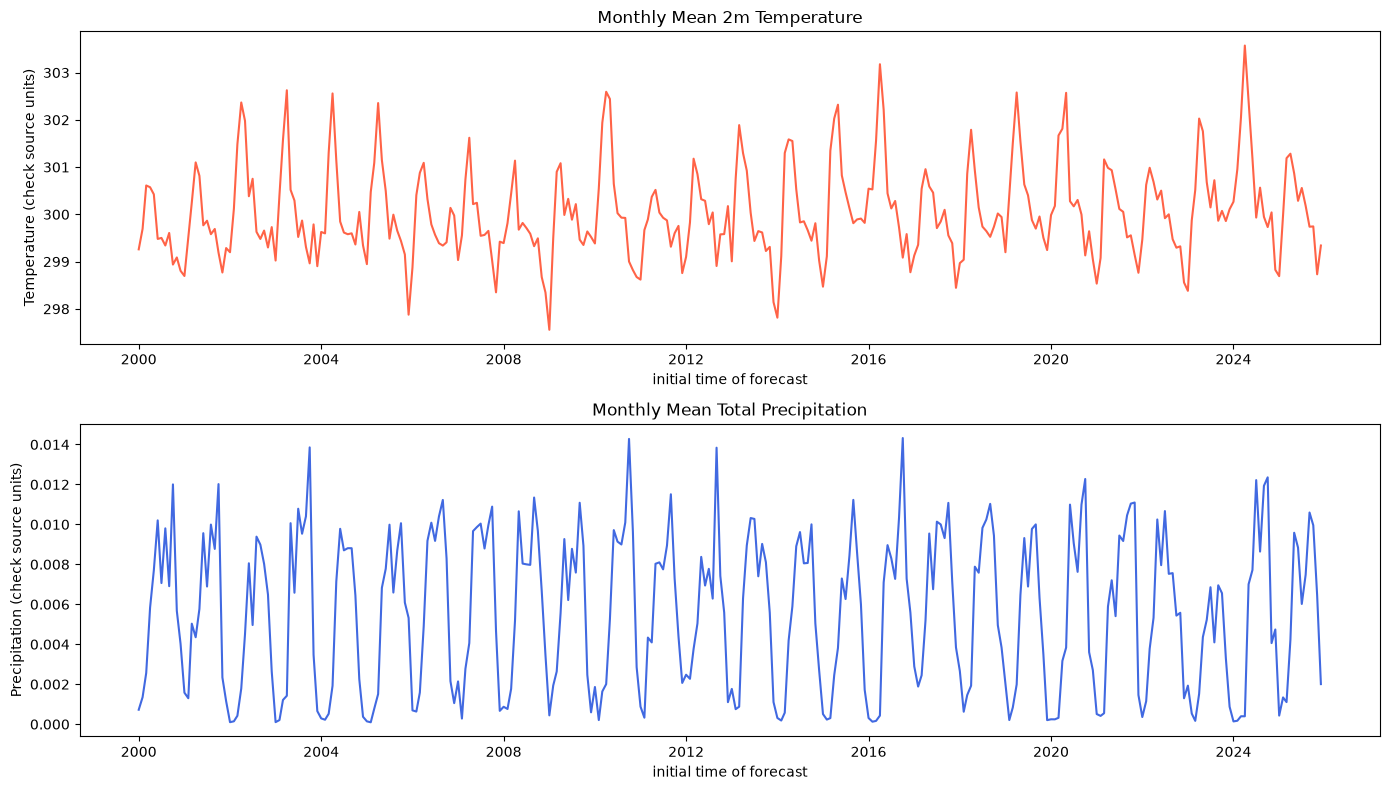

In [7]:
monthly_mean = ds[["t2m", "tp"]].mean(
    dim=["latitude", "longitude"],
    skipna=True
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

monthly_mean["t2m"].plot(
    ax=axes[0],
    color="tomato"
)
axes[0].set_title("Monthly Mean 2m Temperature")
axes[0].set_ylabel("Temperature (check source units)")

monthly_mean["tp"].plot(
    ax=axes[1],
    color="royalblue"
)
axes[1].set_title("Monthly Mean Total Precipitation")
axes[1].set_ylabel("Precipitation (check source units)")

plt.tight_layout()
plt.show()

In [8]:
statistics = []

for var in ds.data_vars:
    da = ds[var]

    statistics.append({
        "variable": var,
        "min": float(da.min(skipna=True).values),
        "max": float(da.max(skipna=True).values),
        "mean": float(da.mean(skipna=True).values),
        "std": float(da.std(skipna=True).values),
        "missing_count": int(da.isnull().sum().values)
    })

statistics_df = pd.DataFrame(statistics)

display(statistics_df.round(4))

,variable,min,max,mean,std,missing_count
0,d2m,287.5192,299.0603,296.1137,1.6366,225264
1,t2m,294.3542,304.9009,300.0502,1.1360,225264
2,swvl1,0.0494,0.4909,0.3689,0.0987,225264
3,swvl2,0.0591,0.4938,0.3708,0.0973,225264
4,swvl3,0.0768,0.5065,0.3733,0.0878,225264
5,swvl4,0.1991,0.5157,0.4257,0.0573,225264
6,pev,-0.0575,-0.0027,-0.0077,0.0039,225264
7,tp,0.0000,0.0289,0.0056,0.0042,225264


## 4. Data Quality Assessment

### Missing Data Analysis

Identify spatial and temporal missing-value patterns
across ERA5-Land variables.

In [9]:
# Missing values by variable
missing_summary = []

for var in ds.data_vars:
    da = ds[var]

    missing_summary.append({
        "variable": var,
        "total_values": da.size,
        "missing_values": int(da.isnull().sum().values),
        "missing_percentage": (
            float(da.isnull().mean().values) * 100
        )
    })

missing_df = pd.DataFrame(missing_summary)

display(missing_df.round(2))

,variable,total_values,missing_values,missing_percentage
0,d2m,379392,225264,59.38
1,t2m,379392,225264,59.38
2,swvl1,379392,225264,59.38
3,swvl2,379392,225264,59.38
4,swvl3,379392,225264,59.38
5,swvl4,379392,225264,59.38
6,pev,379392,225264,59.38
7,tp,379392,225264,59.38


In [10]:
# Spatial availability across all months
spatial_availability = ds["t2m"].notnull().any(
    dim="valid_time"
)

# Cells that have data in every month
spatial_complete = ds["t2m"].notnull().all(
    dim="valid_time"
)

print("Total grid cells:", 32 * 38)

print(
    "Cells with at least one valid observation:",
    int(spatial_availability.sum().values)
)

print(
    "Cells with complete observations:",
    int(spatial_complete.sum().values)
)

print(
    "Cells with intermittent missing values:",
    int(
        (
            spatial_availability & ~spatial_complete
        ).sum().values
    )
)

Total grid cells: 1216
Cells with at least one valid observation: 494
Cells with complete observations: 494
Cells with intermittent missing values: 0


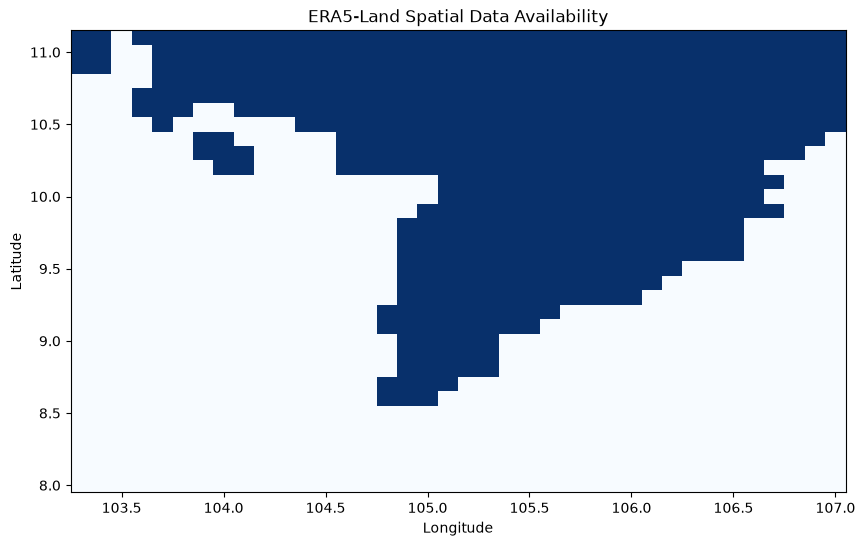

In [11]:
plt.figure(figsize=(10, 6))

spatial_availability.plot(
    cmap="Blues",
    add_colorbar=False
)

plt.title("ERA5-Land Spatial Data Availability")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

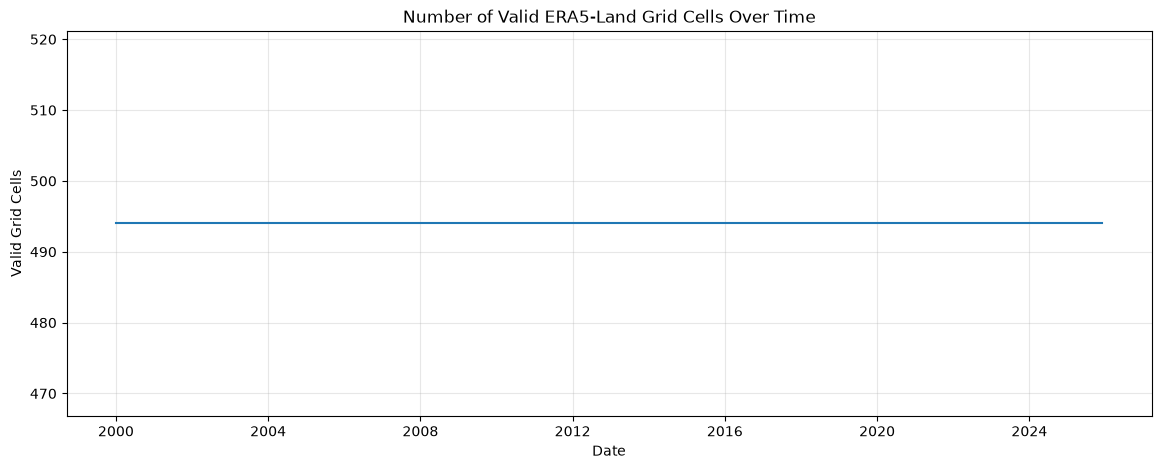

Minimum valid cells: 494
Maximum valid cells: 494
Average valid cells: 494.0


In [12]:
# Count valid grid cells for each month
valid_cells_per_month = (
    ds["t2m"]
    .notnull()
    .sum(dim=["latitude", "longitude"])
)

plt.figure(figsize=(14, 5))

valid_cells_per_month.plot()

plt.title("Number of Valid ERA5-Land Grid Cells Over Time")
plt.xlabel("Date")
plt.ylabel("Valid Grid Cells")
plt.grid(alpha=0.3)

plt.show()

print("Minimum valid cells:", int(valid_cells_per_month.min().values))
print("Maximum valid cells:", int(valid_cells_per_month.max().values))
print("Average valid cells:", round(float(valid_cells_per_month.mean().values), 2))

Section 4 – Spatial Processing

### 4.1. Load GADM Administrative Boundaries

Read the original GADM Vietnam GeoJSON and inspect its structure.

In [13]:
region_gdf = gpd.read_file(GADM_FILE)

print("GADM loaded successfully!")
print("Shape:", region_gdf.shape)

print("\nColumns:")
print(region_gdf.columns.tolist())

print("\nCoordinate Reference System:")
print(region_gdf.crs)

display(region_gdf.head())

GADM loaded successfully!
Shape: (63, 12)

Columns:
['GID_1', 'GID_0', 'COUNTRY', 'NAME_1', 'VARNAME_1', 'NL_NAME_1', 'TYPE_1', 'ENGTYPE_1', 'CC_1', 'HASC_1', 'ISO_1', 'geometry']

Coordinate Reference System:
EPSG:4326


,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry
0,VNM.1_1,VNM,Vietnam,AnGiang,AnGiang,NA,Tỉnh,Province,NA,VN.AG,VN-44,"MULTIPOLYGON (((105.5486 10.4295, 105.5495 10...."
1,VNM.7_1,VNM,Vietnam,BàRịa-VũngTàu,BaRia-VungTau,NA,Tỉnh,Province,NA,VN.BV,NA,"MULTIPOLYGON (((107.0901 10.324, 107.0889 10.3..."
2,VNM.3_1,VNM,Vietnam,BắcGiang,BacGiang,NA,Tỉnh,Province,NA,VN.BG,NA,"MULTIPOLYGON (((106.2838 21.1323, 106.2734 21...."
3,VNM.4_1,VNM,Vietnam,BắcKạn,BacKan,NA,Tỉnh,Province,NA,VN.BK,NA,"MULTIPOLYGON (((105.8724 21.8558, 105.8629 21...."
4,VNM.2_1,VNM,Vietnam,BạcLiêu,BacLieu,NA,Tỉnh,Province,NA,VN.BL,NA,"MULTIPOLYGON (((105.4244 9.0213, 105.4164 9.01..."


In [14]:
print("Available administrative levels:")
print(region_gdf["TYPE_1"].value_counts(dropna=False))

print("\nProvince names:")
province_names = sorted(
    region_gdf["NAME_1"].dropna().unique()
)

for province in province_names:
    print(province)

print("\nTotal administrative units:", len(province_names))

Available administrative levels:
TYPE_1
Tỉnh        58
Thànhphố     5
Name: count, dtype: int64

Province names:
AnGiang
BàRịa-VũngTàu
BìnhDương
BìnhPhước
BìnhThuận
BìnhĐịnh
BạcLiêu
BắcGiang
BắcKạn
BắcNinh
BếnTre
CaoBằng
CàMau
CầnThơ
GiaLai
HoàBình
HàGiang
HàNam
HàNội
HàTĩnh
HưngYên
HảiDương
HảiPhòng
HậuGiang
HồChíMinh
KhánhHòa
KiênGiang
KonTum
LaiChâu
LongAn
LàoCai
LâmĐồng
LạngSơn
NamĐịnh
NghệAn
NinhBình
NinhThuận
PhúThọ
PhúYên
QuảngBình
QuảngNam
QuảngNgãi
QuảngNinh
QuảngTrị
SócTrăng
SơnLa
ThanhHóa
TháiBình
TháiNguyên
ThừaThiênHuế
TiềnGiang
TràVinh
TuyênQuang
TâyNinh
VĩnhLong
VĩnhPhúc
YênBái
ĐiệnBiên
ĐàNẵng
ĐắkLắk
ĐắkNông
ĐồngNai
ĐồngTháp

Total administrative units: 63


In [15]:
MEKONG_PROVINCES = [
    "AnGiang",
    "BạcLiêu",
    "BếnTre",
    "CàMau",
    "CầnThơ",
    "ĐồngTháp",
    "HậuGiang",
    "KiênGiang",
    "LongAn",
    "SócTrăng",
    "TiềnGiang",
    "TràVinh",
    "VĩnhLong"
]

In [16]:
available_provinces = set(region_gdf["NAME_1"].dropna())

found_provinces = [
    name for name in MEKONG_PROVINCES
    if name in available_provinces
]

missing_provinces = [
    name for name in MEKONG_PROVINCES
    if name not in available_provinces
]

print("Expected provinces:", len(MEKONG_PROVINCES))
print("Found provinces:", len(found_provinces))
print("Missing provinces:", missing_provinces)

print("\nMatched provinces:")
for province in found_provinces:
    print("-", province)

Expected provinces: 13
Found provinces: 13
Missing provinces: []

Matched provinces:
- AnGiang
- BạcLiêu
- BếnTre
- CàMau
- CầnThơ
- ĐồngTháp
- HậuGiang
- KiênGiang
- LongAn
- SócTrăng
- TiềnGiang
- TràVinh
- VĩnhLong


In [17]:
if len(found_provinces) != len(MEKONG_PROVINCES):
    raise ValueError(
        "Some provinces were not found. "
        "Please check GADM province names."
    )

mekong_gdf = region_gdf[
    region_gdf["NAME_1"].isin(MEKONG_PROVINCES)
].copy()

print("Selected administrative units:", len(mekong_gdf))

display(
    mekong_gdf[["NAME_1", "TYPE_1", "geometry"]]
)

Selected administrative units: 13


,NAME_1,TYPE_1,geometry
0,AnGiang,Tỉnh,"MULTIPOLYGON (((105.5486 10.4295, 105.5495 10...."
4,BạcLiêu,Tỉnh,"MULTIPOLYGON (((105.4244 9.0213, 105.4164 9.01..."
6,BếnTre,Tỉnh,"MULTIPOLYGON (((106.719 10.0337, 106.7086 10.0..."
11,CàMau,Tỉnh,"MULTIPOLYGON (((104.8535 8.4202, 104.8576 8.41..."
12,CầnThơ,Thànhphố,"MULTIPOLYGON (((105.5696 9.9839, 105.5631 9.98..."
19,ĐồngTháp,Tỉnh,"MULTIPOLYGON (((105.8253 10.1489, 105.8185 10...."
27,HậuGiang,Tỉnh,"MULTIPOLYGON (((105.4929 9.5907, 105.493 9.586..."
32,KiênGiang,Tỉnh,"MULTIPOLYGON (((103.4689 9.256, 103.4674 9.254..."
38,LongAn,Tỉnh,"MULTIPOLYGON (((106.5042 10.4209, 106.502 10.4..."
50,SócTrăng,Tỉnh,"MULTIPOLYGON (((105.8462 9.3541, 105.8515 9.35..."


In [18]:
print("CRS:", mekong_gdf.crs)

print("\nGeometry types:")
print(mekong_gdf.geom_type.value_counts())

print("\nInvalid geometries:")
print((~mekong_gdf.geometry.is_valid).sum())

print("\nEmpty geometries:")
print(mekong_gdf.geometry.is_empty.sum())

CRS: EPSG:4326

Geometry types:
MultiPolygon    13
Name: count, dtype: int64

Invalid geometries:
0

Empty geometries:
0


Kiểm tra CRS và geometry

In [19]:
mekong_boundary = mekong_gdf.dissolve()

print("Dissolve completed!")

print("Number of features:", len(mekong_boundary))
print("Geometry type:", mekong_boundary.geom_type.iloc[0])
print("CRS:", mekong_boundary.crs)

display(mekong_boundary)

Dissolve completed!
Number of features: 1
Geometry type: MultiPolygon
CRS: EPSG:4326


,geometry,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1
0,"MULTIPOLYGON (((103.4674 9.2545, 103.4674 9.25...",VNM.1_1,VNM,Vietnam,AnGiang,AnGiang,NA,Tỉnh,Province,NA,VN.AG,VN-44


Visualize boundary

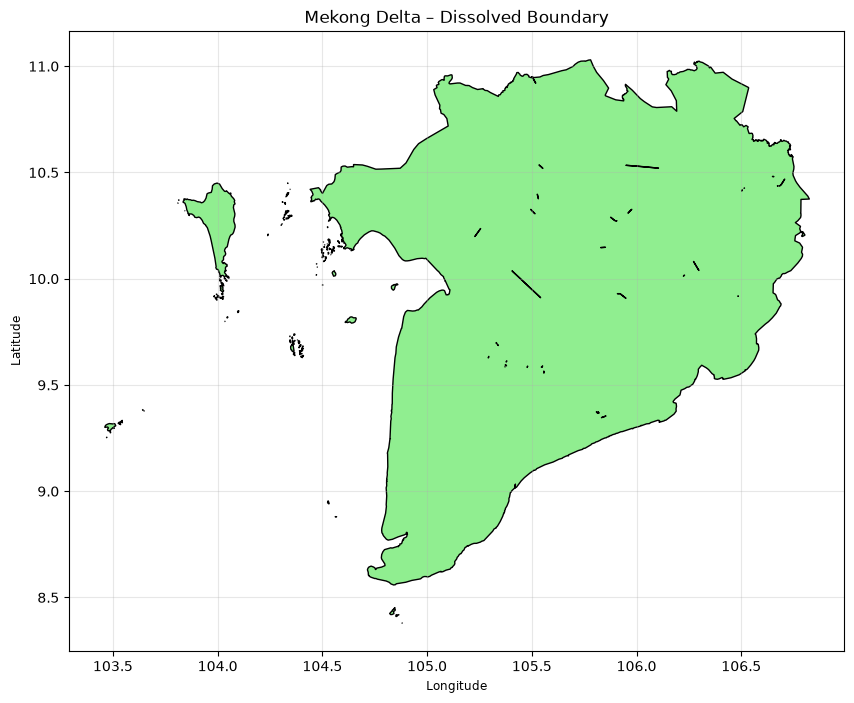

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))

mekong_boundary.plot(
    ax=ax,
    edgecolor="black",
    facecolor="lightgreen"
)

ax.set_title("Mekong Delta – Dissolved Boundary")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.3)

plt.show()

In [21]:
mekong_boundary.to_file(
    BOUNDARY_FILE,
    driver="GeoJSON"
)

print("Boundary exported successfully!")
print("Output:", BOUNDARY_FILE)

Boundary exported successfully!
Output: /home/trang/Drought_prediction/data/silver/boundaries/mekong_delta_boundary.geojson


In [22]:
mask = regionmask.mask_geopandas(
    mekong_boundary,
    ds["longitude"],
    ds["latitude"]
)

print("Mask dimensions:", mask.dims)
print("Mask shape:", mask.shape)

print("\nMask values:")
print(np.unique(mask.values[~np.isnan(mask.values)]))

Mask dimensions: ('latitude', 'longitude')
Mask shape: (32, 38)

Mask values:
[0.]


In [23]:
# Count grid cells inside and outside the Mekong Delta boundary
inside_cells = int((mask == 0).sum().item())
outside_cells = int(mask.isnull().sum().item())

total_cells = mask.size

print("Total grid cells:", total_cells)
print("Inside Mekong Delta:", inside_cells)
print("Outside Mekong Delta:", outside_cells)
print("Check total:", inside_cells + outside_cells)

Total grid cells: 1216
Inside Mekong Delta: 335
Outside Mekong Delta: 881
Check total: 1216


Clipping ERA5-Land

In [24]:
# Keep only grid cells inside the Mekong Delta boundary
clipped = ds.where(mask == 0)

# Count grid cells with at least one valid observation
valid_spatial_cells = clipped["t2m"].notnull().any(
    dim="valid_time"
).sum()

# Count grid cells with complete observations
complete_spatial_cells = clipped["t2m"].notnull().all(
    dim="valid_time"
).sum()

print("Clipping completed!")
print("Original dimensions:", dict(ds.sizes))
print("Clipped dimensions:", dict(clipped.sizes))
print("Grid cells inside boundary:", inside_cells)
print("Grid cells with valid ERA5 data:", int(valid_spatial_cells.item()))
print("Grid cells with complete time series:", int(complete_spatial_cells.item()))

Clipping completed!
Original dimensions: {'valid_time': 312, 'latitude': 32, 'longitude': 38}
Clipped dimensions: {'valid_time': 312, 'latitude': 32, 'longitude': 38}
Grid cells inside boundary: 335
Grid cells with valid ERA5 data: 326
Grid cells with complete time series: 326


In [25]:
# Check dimensions and variables
print("Dimensions:")
print(clipped.sizes)

print("\nVariables:")
print(list(clipped.data_vars))

# Check valid grid cells for each variable
for var in clipped.data_vars:
    valid_cells = clipped[var].notnull().any(dim="valid_time").sum().item()
    missing_values = clipped[var].isnull().sum().item()

    print(
        f"{var}: "
        f"valid_grid_cells={int(valid_cells)}, "
        f"missing_values={int(missing_values)}"
    )

Dimensions:
Frozen({'valid_time': 312, 'latitude': 32, 'longitude': 38})

Variables:
['d2m', 't2m', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'pev', 'tp']
d2m: valid_grid_cells=326, missing_values=277680
t2m: valid_grid_cells=326, missing_values=277680
swvl1: valid_grid_cells=326, missing_values=277680
swvl2: valid_grid_cells=326, missing_values=277680
swvl3: valid_grid_cells=326, missing_values=277680
swvl4: valid_grid_cells=326, missing_values=277680
pev: valid_grid_cells=326, missing_values=277680
tp: valid_grid_cells=326, missing_values=277680


In [26]:
# Save clipped ERA5-Land dataset to Silver layer
clipped.to_netcdf(CLIPPED_FILE)

print("Silver dataset saved!")
print("Path:", CLIPPED_FILE)
print("File exists:", CLIPPED_FILE.exists())
print("File size (MB):", round(CLIPPED_FILE.stat().st_size / (1024**2), 2))

Silver dataset saved!
Path: /home/trang/Drought_prediction/data/silver/era5_land/era5_land_mekong_delta_2000_2025.nc
File exists: True
File size (MB): 11.66


In [27]:
silver_ds = xr.open_dataset(CLIPPED_FILE)

print("Silver dataset verification:")
print("Dimensions:", dict(silver_ds.sizes))
print("Variables:", list(silver_ds.data_vars))
print("Time range:", silver_ds.valid_time.min().values, "to", silver_ds.valid_time.max().values)

Silver dataset verification:
Dimensions: {'valid_time': 312, 'latitude': 32, 'longitude': 38}
Variables: ['d2m', 't2m', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'pev', 'tp']
Time range: 2000-01-01T00:00:00.000000000 to 2025-12-01T00:00:00.000000000


In [28]:
quality_records = []

for var in silver_ds.data_vars:
    da = silver_ds[var]

    total_values = da.size
    valid_values = int(da.notnull().sum().item())
    missing_values = total_values - valid_values

    valid_grid_cells = int(
        da.notnull().any(dim="valid_time").sum().item()
    )

    stats = {
        "variable": var,
        "total_values": total_values,
        "valid_values": valid_values,
        "missing_values": missing_values,
        "missing_pct": round(missing_values / total_values * 100, 2),
        "valid_grid_cells": valid_grid_cells,
        "min": float(da.min(skipna=True).item()),
        "max": float(da.max(skipna=True).item()),
        "mean": float(da.mean(skipna=True).item()),
        "std": float(da.std(skipna=True).item())
    }

    quality_records.append(stats)

quality_report = pd.DataFrame(quality_records)

display(quality_report)

,variable,total_values,valid_values,missing_values,missing_pct,valid_grid_cells,min,max,mean,std
0,d2m,379392,101712,277680,73.19,326,288.806274,299.019287,296.269348,1.495107
1,t2m,379392,101712,277680,73.19,326,297.018799,304.783691,300.108826,1.036875
2,swvl1,379392,101712,277680,73.19,326,0.049408,0.490219,0.365697,0.099530
3,swvl2,379392,101712,277680,73.19,326,0.059143,0.493179,0.368075,0.098260
4,swvl3,379392,101712,277680,73.19,326,0.076782,0.506348,0.370849,0.088321
5,swvl4,379392,101712,277680,73.19,326,0.199142,0.514709,0.423107,0.056956
6,pev,379392,101712,277680,73.19,326,-0.050146,-0.002669,-0.007264,0.003184
7,tp,379392,101712,277680,73.19,326,0.000008,0.021091,0.005581,0.004004


In [29]:
quality_report.to_csv(QUALITY_REPORT, index=False)

print("Quality report saved!")
print("Path:", QUALITY_REPORT)
print("File exists:", QUALITY_REPORT.exists())

Quality report saved!
Path: /home/trang/Drought_prediction/data/silver/era5_land/quality_report.csv
File exists: True


In [33]:
silver_metadata = {
    "dataset_name": "ERA5-Land Mekong Delta",
    "source_file": str(BRONZE_FILE),
    "output_file": str(CLIPPED_FILE),
    "format": "NetCDF",
    "spatial_boundary": "13 provinces/cities in the historical Mekong Delta study boundary",
    "crs": "EPSG:4326",
    "time_range": {
        "start": str(pd.Timestamp(silver_ds.valid_time.min().values).date()),
        "end": str(pd.Timestamp(silver_ds.valid_time.max().values).date())
    },
    "frequency": "Monthly",
    "dimensions": {
        key: int(value)
        for key, value in silver_ds.sizes.items()
    },
    "variables": list(silver_ds.data_vars),
    "valid_grid_cells": 326,
    "missing_data_policy": "Preserve NaN; no imputation",
    "transformations": [
        "Spatial clipping using dissolved Mekong Delta boundary",
        "Preserve original ERA5-Land variable values and units",
        "Retain original grid dimensions"
    ]
}

SILVER_METADATA = ERA5_DIR / "metadata.json"

with open(SILVER_METADATA, "w", encoding="utf-8") as f:
    json.dump(silver_metadata, f, indent=4, ensure_ascii=False)

print("Silver metadata saved:", SILVER_METADATA)

Silver metadata saved: /home/trang/Drought_prediction/data/silver/era5_land/metadata.json


Bước 5: Duplicate Detection

In [34]:
# Load previously clipped Silver dataset
silver_ds = xr.open_dataset(CLIPPED_FILE)

print("Dataset loaded!")
print("Dimensions:", dict(silver_ds.sizes))
print("Variables:", list(silver_ds.data_vars))

Dataset loaded!
Dimensions: {'valid_time': 312, 'latitude': 32, 'longitude': 38}
Variables: ['d2m', 't2m', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'pev', 'tp']


In [35]:
# Check duplicated time coordinates
duplicate_times = silver_ds.indexes["valid_time"].duplicated().sum()

# Check duplicated spatial coordinates
duplicate_latitudes = silver_ds.indexes["latitude"].duplicated().sum()
duplicate_longitudes = silver_ds.indexes["longitude"].duplicated().sum()

print("Duplicate valid_time:", duplicate_times)
print("Duplicate latitude:", duplicate_latitudes)
print("Duplicate longitude:", duplicate_longitudes)

print("\nCoordinate validation:")
print("Unique timestamps:", silver_ds.indexes["valid_time"].is_unique)
print("Unique latitudes:", silver_ds.indexes["latitude"].is_unique)
print("Unique longitudes:", silver_ds.indexes["longitude"].is_unique)

Duplicate valid_time: 0
Duplicate latitude: 0
Duplicate longitude: 0

Coordinate validation:
Unique timestamps: True
Unique latitudes: True
Unique longitudes: True


In [36]:
import pandas as pd

coordinate_df = pd.MultiIndex.from_product(
    [
        silver_ds.valid_time.values,
        silver_ds.latitude.values,
        silver_ds.longitude.values
    ],
    names=["valid_time", "latitude", "longitude"]
).to_frame(index=False)

duplicate_records = coordinate_df.duplicated(
    subset=["valid_time", "latitude", "longitude"]
).sum()

print("Total coordinate combinations:", len(coordinate_df))
print("Duplicate coordinate combinations:", duplicate_records)

Total coordinate combinations: 379392
Duplicate coordinate combinations: 0


Bước 6: Missing Value Assessment

In [37]:
# Identify grid cells inside the study boundary
inside_mask = mask == 0

# Identify grid cells with valid data
valid_mask = silver_ds["t2m"].notnull().any(dim="valid_time")

# Classify grid cells
inside_without_data = inside_mask & ~valid_mask
inside_with_data = inside_mask & valid_mask

outside_boundary = mask.isnull()

print("Grid cells inside boundary:", int(inside_mask.sum().item()))
print("Grid cells inside with data:", int(inside_with_data.sum().item()))
print("Grid cells inside without data:", int(inside_without_data.sum().item()))
print("Grid cells outside boundary:", int(outside_boundary.sum().item()))

Grid cells inside boundary: 335
Grid cells inside with data: 326
Grid cells inside without data: 9
Grid cells outside boundary: 881


In [38]:
# Count missing observations over time for each valid grid cell
temporal_missing = silver_ds["t2m"].isnull().sum(dim="valid_time")

# Only evaluate cells inside the boundary
temporal_missing_inside = temporal_missing.where(inside_mask)

# Count cells with intermittent missing observations
intermittent_missing_cells = (
    (temporal_missing_inside > 0) &
    (temporal_missing_inside < silver_ds.sizes["valid_time"])
).sum()

# Count cells missing all observations
all_missing_cells = (
    temporal_missing_inside == silver_ds.sizes["valid_time"]
).sum()

print("Grid cells with intermittent missing:", int(intermittent_missing_cells.item()))
print("Grid cells missing all observations:", int(all_missing_cells.item()))

Grid cells with intermittent missing: 0
Grid cells missing all observations: 9


Bước 7: Xử lý grid cells không có dữ liệu

In [39]:
# Identify spatial cells with valid observations
valid_spatial_mask = silver_ds["t2m"].notnull().any(dim="valid_time")

# Remove rows and columns that contain no valid observations
silver_clean = silver_ds.where(
    valid_spatial_mask,
    drop=True
)

print("Original dimensions:", dict(silver_ds.sizes))
print("Cleaned dimensions:", dict(silver_clean.sizes))

print(
    "Valid grid cells:",
    int(valid_spatial_mask.sum().item())
)

print(
    "Remaining missing values:",
    int(silver_clean["t2m"].isnull().sum().item())
)

Original dimensions: {'valid_time': 312, 'latitude': 32, 'longitude': 38}
Cleaned dimensions: {'valid_time': 312, 'latitude': 25, 'longitude': 25}
Valid grid cells: 326
Remaining missing values: 93288


In [40]:
# Check missing values after spatial cleaning
for var in silver_clean.data_vars:
    da = silver_clean[var]

    valid_cells = int(
        da.notnull().any(dim="valid_time").sum().item()
    )

    all_missing_cells = int(
        da.isnull().all(dim="valid_time").sum().item()
    )

    intermittent_missing = int(
        (
            da.notnull().any(dim="valid_time")
            & da.isnull().any(dim="valid_time")
        ).sum().item()
    )

    print(f"\nVariable: {var}")
    print("Valid grid cells:", valid_cells)
    print("All-missing grid cells:", all_missing_cells)
    print("Intermittent missing cells:", intermittent_missing)


Variable: d2m
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: t2m
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: swvl1
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: swvl2
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: swvl3
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: swvl4
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: pev
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0

Variable: tp
Valid grid cells: 326
All-missing grid cells: 299
Intermittent missing cells: 0


In [41]:
# Define physical validation rules
validation_rules = {
    "d2m": {"min": 150, "max": 350},   # Kelvin
    "t2m": {"min": 150, "max": 350},   # Kelvin
    "swvl1": {"min": 0, "max": 1},     # m3/m3
    "swvl2": {"min": 0, "max": 1},
    "swvl3": {"min": 0, "max": 1},
    "swvl4": {"min": 0, "max": 1},
    "pev": {"min": None, "max": 1},    # m, negative values are possible
    "tp": {"min": 0, "max": 1}         # m, non-negative
}

invalid_records = []

for var, rule in validation_rules.items():
    da = silver_clean[var]

    invalid_mask = xr.zeros_like(da, dtype=bool)

    if rule["min"] is not None:
        invalid_mask = invalid_mask | (da < rule["min"])

    if rule["max"] is not None:
        invalid_mask = invalid_mask | (da > rule["max"])

    invalid_count = int(invalid_mask.sum().item())

    invalid_records.append({
        "variable": var,
        "invalid_count": invalid_count,
        "allowed_min": rule["min"],
        "allowed_max": rule["max"]
    })

invalid_report = pd.DataFrame(invalid_records)

display(invalid_report)

,variable,invalid_count,allowed_min,allowed_max
0,d2m,0,150.0,350
1,t2m,0,150.0,350
2,swvl1,0,0.0,1
3,swvl2,0,0.0,1
4,swvl3,0,0.0,1
5,swvl4,0,0.0,1
6,pev,0,NaN,1
7,tp,0,0.0,1


Bước 9: Outlier Detection

In [42]:
outlier_records = []

for var in silver_clean.data_vars:
    values = silver_clean[var].values.flatten()

    # Remove NaN values
    values = values[~np.isnan(values)]

    q1 = np.percentile(values, 25)
    q3 = np.percentile(values, 75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = int(
        ((values < lower_bound) | (values > upper_bound)).sum()
    )

    outlier_records.append({
        "variable": var,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_pct": round(outlier_count / len(values) * 100, 3)
    })

outlier_report = pd.DataFrame(outlier_records)

display(outlier_report)

,variable,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
0,d2m,295.156799,297.378723,2.221924,291.823914,300.711609,461,0.453
1,t2m,299.476929,300.626465,1.149536,297.752625,302.350769,4469,4.394
2,swvl1,0.294952,0.448166,0.153214,0.065132,0.677986,78,0.077
3,swvl2,0.292084,0.450062,0.157978,0.055117,0.687029,0,0.000
4,swvl3,0.304134,0.442474,0.138340,0.096624,0.649984,72,0.071
5,swvl4,0.383602,0.468536,0.084934,0.256201,0.595938,324,0.319
6,pev,-0.007978,-0.005620,0.002358,-0.011516,-0.002082,5066,4.981
7,tp,0.001525,0.008712,0.007187,-0.009255,0.019492,12,0.012


Phân tích outlier theo tháng

In [43]:
# Convert valid grid observations into a DataFrame
analysis_df = silver_clean.to_dataframe().reset_index()

# Keep only rows with valid climate observations
analysis_df = analysis_df.dropna(subset=["t2m"])

# Extract calendar month
analysis_df["month"] = analysis_df["valid_time"].dt.month

print("Analysis shape:", analysis_df.shape)
print("\nColumns:")
print(analysis_df.columns.tolist())

display(analysis_df.head())

Analysis shape: (101712, 14)

Columns:
['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'pev', 'tp', 'number', 'expver', 'month']


,valid_time,latitude,longitude,d2m,t2m,swvl1,swvl2,swvl3,swvl4,pev,tp,number,expver,month
13,2000-01-01,11.0,105.7,293.165161,300.119019,0.303757,0.305405,0.366119,0.474777,-0.007460,0.000670,0,0001,1
19,2000-01-01,11.0,106.3,293.528442,299.745972,0.309219,0.306824,0.364578,0.471451,-0.007120,0.000832,0,0001,1
32,2000-01-01,10.9,105.1,293.647583,299.824097,0.178589,0.198395,0.271515,0.382568,-0.007319,0.000600,0,0001,1
33,2000-01-01,10.9,105.2,293.792114,299.802612,0.198517,0.215652,0.288864,0.384689,-0.007280,0.000649,0,0001,1
35,2000-01-01,10.9,105.4,293.696411,299.751831,0.202850,0.218765,0.296021,0.384338,-0.006971,0.000787,0,0001,1


In [44]:
monthly_outlier_records = []

for var in silver_clean.data_vars:

    for month in range(1, 13):

        values = analysis_df.loc[
            analysis_df["month"] == month, var
        ].dropna().values

        q1 = np.percentile(values, 25)
        q3 = np.percentile(values, 75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outlier_count = int(
            ((values < lower) | (values > upper)).sum()
        )

        monthly_outlier_records.append({
            "variable": var,
            "month": month,
            "sample_count": len(values),
            "outlier_count": outlier_count,
            "outlier_pct": round(
                outlier_count / len(values) * 100, 3
            )
        })

monthly_outlier_report = pd.DataFrame(
    monthly_outlier_records
)

display(monthly_outlier_report)

,variable,month,sample_count,outlier_count,outlier_pct
0,d2m,1,8476,209,2.466
1,d2m,2,8476,19,0.224
2,d2m,3,8476,11,0.130
3,d2m,4,8476,140,1.652
4,d2m,5,8476,446,5.262
...,...,...,...,...,...
91,tp,8,8476,142,1.675
92,tp,9,8476,113,1.333
93,tp,10,8476,40,0.472
94,tp,11,8476,330,3.893


In [45]:
# Group data by each grid cell and calendar month
spatial_monthly_outliers = []

for var in silver_clean.data_vars:
    grouped = analysis_df.groupby(
        ["latitude", "longitude", "month"]
    )[var]

    for (lat, lon, month), values in grouped:
        values = values.dropna()

        if len(values) < 10:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outlier_count = (
            (values < lower) | (values > upper)
        ).sum()

        spatial_monthly_outliers.append({
            "variable": var,
            "latitude": lat,
            "longitude": lon,
            "month": month,
            "sample_count": len(values),
            "outlier_count": int(outlier_count),
            "outlier_pct": round(
                outlier_count / len(values) * 100, 3
            )
        })

spatial_outlier_report = pd.DataFrame(
    spatial_monthly_outliers
)

display(spatial_outlier_report.head())

,variable,latitude,longitude,month,sample_count,outlier_count,outlier_pct
0,d2m,8.6,104.8,1,26,0,0.000
1,d2m,8.6,104.8,2,26,0,0.000
2,d2m,8.6,104.8,3,26,0,0.000
3,d2m,8.6,104.8,4,26,0,0.000
4,d2m,8.6,104.8,5,26,1,3.846


In [46]:
spatial_outlier_summary = (
    spatial_outlier_report
    .groupby("variable")
    .agg(
        total_groups=("outlier_count", "size"),
        groups_with_outliers=(
            "outlier_count",
            lambda x: (x > 0).sum()
        ),
        total_outliers=("outlier_count", "sum"),
        mean_outlier_pct=("outlier_pct", "mean"),
        max_outlier_pct=("outlier_pct", "max")
    )
    .reset_index()
)

display(spatial_outlier_summary)

,variable,total_groups,groups_with_outliers,total_outliers,mean_outlier_pct,max_outlier_pct
0,d2m,3912,1276,1973,1.939716,15.385
1,pev,3912,1509,2863,2.814726,23.077
2,swvl1,3912,2017,3215,3.160771,19.231
3,swvl2,3912,2204,4527,4.450698,30.769
4,swvl3,3912,1732,2959,2.909105,26.923
5,swvl4,3912,1009,2049,2.014453,23.077
6,t2m,3912,1163,1941,1.908285,19.231
7,tp,3912,1520,2510,2.467664,19.231


In [47]:
display(
    spatial_outlier_report
    .sort_values("outlier_pct", ascending=False)
    .head(20)
)

,variable,latitude,longitude,month,sample_count,outlier_count,outlier_pct
14397,swvl2,10.4,104.7,10,26,8,30.769
17347,swvl3,10.0,105.1,8,26,7,26.923
22892,swvl4,10.6,106.2,9,26,6,23.077
12337,swvl2,9.4,105.3,2,26,6,23.077
26974,pev,10.7,105.9,11,26,6,23.077
12510,swvl2,9.5,105.4,7,26,6,23.077
15254,swvl2,10.7,106.1,3,26,6,23.077
23096,swvl4,10.7,106.2,9,26,6,23.077
22676,swvl4,10.5,106.2,9,26,6,23.077
11834,swvl2,8.8,105.1,3,26,6,23.077


In [56]:
print("Shape:", analysis_df.shape)
print("Columns:", analysis_df.columns.tolist())

print("\nLatitude range:")
print(analysis_df["latitude"].min(), analysis_df["latitude"].max())

print("\nLongitude range:")
print(analysis_df["longitude"].min(), analysis_df["longitude"].max())

print("\nMonth values:")
print(analysis_df["month"].unique())

Shape: (101712, 14)
Columns: ['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'pev', 'tp', 'number', 'expver', 'month']

Latitude range:
8.600000000000009 11.0

Longitude range:
103.89999999999996 106.7999999999998

Month values:
[ 1  2  3  4  5  6  7  8  9 10 11 12]


In [57]:
target = analysis_df[
    np.isclose(analysis_df["latitude"], 10.4)
    & np.isclose(analysis_df["longitude"], 104.7)
    & (analysis_df["month"] == 10)
].sort_values("valid_time")

print("Number of records:", len(target))

display(target[["valid_time", "swvl2"]])

Number of records: 26


,valid_time,swvl2
5778,2000-10-01,0.487259
13278,2001-10-01,0.487839
20778,2002-10-01,0.468445
28278,2003-10-01,0.483017
35778,2004-10-01,0.448746
43278,2005-10-01,0.481934
50778,2006-10-01,0.483734
58278,2007-10-01,0.483795
65778,2008-10-01,0.482468
73278,2009-10-01,0.468674


In [58]:
print(
    analysis_df[
        (analysis_df["latitude"].round(1) == 10.4)
        & (analysis_df["longitude"].round(1) == 104.7)
    ][["latitude", "longitude"]]
    .drop_duplicates()
    .to_string(index=False)
)

 latitude  longitude
     10.4      104.7


In [59]:
target = analysis_df[
    (analysis_df["latitude"].round(1) == 10.4)
    & (analysis_df["longitude"].round(1) == 104.7)
    & (analysis_df["month"] == 10)
].sort_values("valid_time")

print("Number of records:", len(target))

display(target[["valid_time", "swvl2"]])

Number of records: 26


,valid_time,swvl2
5778,2000-10-01,0.487259
13278,2001-10-01,0.487839
20778,2002-10-01,0.468445
28278,2003-10-01,0.483017
35778,2004-10-01,0.448746
43278,2005-10-01,0.481934
50778,2006-10-01,0.483734
58278,2007-10-01,0.483795
65778,2008-10-01,0.482468
73278,2009-10-01,0.468674


In [60]:
q1 = target["swvl2"].quantile(0.25)
q3 = target["swvl2"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

target = target.copy()

target["is_outlier"] = (
    (target["swvl2"] < lower_bound)
    | (target["swvl2"] > upper_bound)
)

print(f"Q1: {q1:.6f}")
print(f"Q3: {q3:.6f}")
print(f"IQR: {iqr:.6f}")
print(f"Lower bound: {lower_bound:.6f}")
print(f"Upper bound: {upper_bound:.6f}")
print(f"Outlier count: {target['is_outlier'].sum()}")

display(
    target[["valid_time", "swvl2", "is_outlier"]]
)

Q1: 0.481258
Q3: 0.483643
IQR: 0.002384
Lower bound: 0.477682
Upper bound: 0.487219
Outlier count: 8


,valid_time,swvl2,is_outlier
5778,2000-10-01,0.487259,True
13278,2001-10-01,0.487839,True
20778,2002-10-01,0.468445,True
28278,2003-10-01,0.483017,False
35778,2004-10-01,0.448746,True
43278,2005-10-01,0.481934,False
50778,2006-10-01,0.483734,False
58278,2007-10-01,0.483795,False
65778,2008-10-01,0.482468,False
73278,2009-10-01,0.468674,True


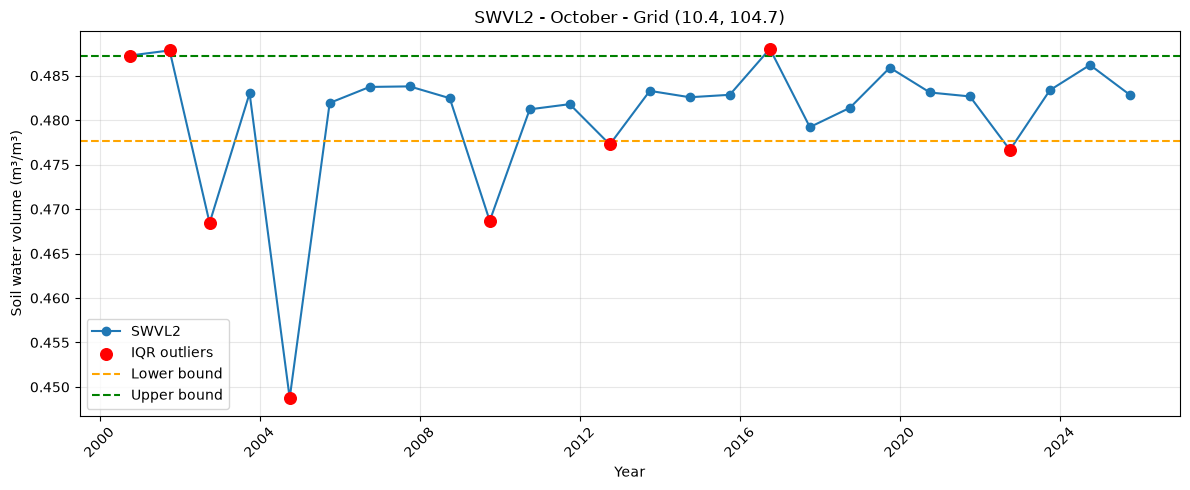

In [61]:
plt.figure(figsize=(12, 5))

plt.plot(
    target["valid_time"],
    target["swvl2"],
    marker="o",
    label="SWVL2"
)

outliers = target[target["is_outlier"]]

plt.scatter(
    outliers["valid_time"],
    outliers["swvl2"],
    color="red",
    s=70,
    label="IQR outliers",
    zorder=3
)

plt.axhline(
    lower_bound,
    color="orange",
    linestyle="--",
    label="Lower bound"
)

plt.axhline(
    upper_bound,
    color="green",
    linestyle="--",
    label="Upper bound"
)

plt.title("SWVL2 - October - Grid (10.4, 104.7)")
plt.xlabel("Year")
plt.ylabel("Soil water volume (m³/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
# Inspect metadata of precipitation and potential evaporation
for var in ["tp", "pev"]:
    print(f"\n{'=' * 50}")
    print(f"Variable: {var}")
    print(f"{'=' * 50}")

    print("Attributes:")
    for key, value in silver_ds[var].attrs.items():
        print(f"  {key}: {value}")

    print("\nEncoding:")
    for key, value in silver_ds[var].encoding.items():
        print(f"  {key}: {value}")

    print("\nStatistics:")
    print(f"  Min: {float(silver_ds[var].min(skipna=True)):.8f}")
    print(f"  Max: {float(silver_ds[var].max(skipna=True)):.8f}")
    print(f"  Mean: {float(silver_ds[var].mean(skipna=True)):.8f}")


Variable: tp
Attributes:
  GRIB_paramId: 228
  GRIB_dataType: fc
  GRIB_numberOfPoints: 1216
  GRIB_typeOfLevel: surface
  GRIB_stepUnits: 1
  GRIB_gridType: regular_ll
  GRIB_uvRelativeToGrid: 0
  GRIB_NV: 0
  GRIB_Nx: 38
  GRIB_Ny: 32
  GRIB_cfName: unknown
  GRIB_cfVarName: tp
  GRIB_gridDefinitionDescription: Latitude/Longitude Grid
  GRIB_iDirectionIncrementInDegrees: 0.1
  GRIB_iScansNegatively: 0
  GRIB_jDirectionIncrementInDegrees: 0.1
  GRIB_jPointsAreConsecutive: 0
  GRIB_jScansPositively: 0
  GRIB_latitudeOfFirstGridPointInDegrees: 11.1
  GRIB_latitudeOfLastGridPointInDegrees: 8.0
  GRIB_longitudeOfFirstGridPointInDegrees: 103.3
  GRIB_longitudeOfLastGridPointInDegrees: 107.0
  GRIB_missingValue: 3.4028234663852886e+38
  GRIB_name: Total precipitation
  GRIB_shortName: tp
  GRIB_totalNumber: 0
  GRIB_units: m
  long_name: Total precipitation
  units: m
  standard_name: unknown
  GRIB_surface: 0.0

Encoding:
  dtype: float32
  zlib: False
  szip: False
  zstd: False
  bzip2:

In [64]:
bronze_ds = xr.open_dataset(BRONZE_FILE)

for dataset_name, dataset in [
    ("BRONZE", bronze_ds),
    ("SILVER", silver_ds)
]:
    print(f"\n{'=' * 65}")
    print(dataset_name)
    print(f"{'=' * 65}")

    for var in ["tp", "pev"]:
        da = dataset[var]

        print(f"\n--- {var} ---")
        print("Attributes:", da.attrs)
        print("Units:", da.attrs.get("units", "NOT FOUND"))
        print("GRIB paramId:", da.attrs.get("GRIB_paramId", "NOT FOUND"))

        values = da.values
        valid = values[np.isfinite(values)]

        print("Min:", np.min(valid))
        print("Max:", np.max(valid))
        print("Mean:", np.mean(valid))
        print("Negative count:", np.sum(valid < 0))
        print("Zero count:", np.sum(valid == 0))
        print("Positive count:", np.sum(valid > 0))


BRONZE

--- tp ---
Attributes: {'GRIB_paramId': np.int64(228), 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': np.int64(1216), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(38), 'GRIB_Ny': np.int64(32), 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'tp', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.1), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(11.1), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(8.0), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(103.3), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(107.0), 'GRIB_missingValue': np.float64(3.4028234663852886e+38), 'GRIB_name': 'Total precipitation

In [65]:
for var in ["tp", "pev"]:
    monthly_stats = silver_ds[var].mean(
        dim=["latitude", "longitude"],
        skipna=True
    ).to_series()

    print(f"\n--- {var}: monthly spatial mean ---")
    display(
        monthly_stats.loc["2022-09-01":"2024-02-01"]
    )


--- tp: monthly spatial mean ---


valid_time
2022-09-01    0.007741
2022-10-01    0.005680
2022-11-01    0.006131
2022-12-01    0.001559
2023-01-01    0.001871
2023-02-01    0.000589
2023-03-01    0.000074
2023-04-01    0.001554
2023-05-01    0.004554
2023-06-01    0.005294
2023-07-01    0.006827
2023-08-01    0.004097
2023-09-01    0.006993
2023-10-01    0.006561
2023-11-01    0.003493
2023-12-01    0.000931
2024-01-01    0.000145
2024-02-01    0.000099
Name: tp, dtype: float32


--- pev: monthly spatial mean ---


valid_time
2022-09-01   -0.004466
2022-10-01   -0.004187
2022-11-01   -0.004177
2022-12-01   -0.005288
2023-01-01   -0.004831
2023-02-01   -0.006439
2023-03-01   -0.007627
2023-04-01   -0.006807
2023-05-01   -0.005930
2023-06-01   -0.005053
2023-07-01   -0.004532
2023-08-01   -0.005937
2023-09-01   -0.004373
2023-10-01   -0.004499
2023-11-01   -0.004749
2023-12-01   -0.005581
2024-01-01   -0.006522
2024-02-01   -0.007343
Name: pev, dtype: float32

In [66]:
for var in ["tp", "pev"]:
    print(f"\n{'=' * 55}")
    print(f"COMPARISON: {var}")
    print(f"{'=' * 55}")

    bronze_var = bronze_ds[var]
    silver_var = silver_ds[var]

    # Align common coordinates
    bronze_aligned, silver_aligned = xr.align(
        bronze_var,
        silver_var,
        join="inner"
    )

    b = bronze_aligned.values.flatten()
    s = silver_aligned.values.flatten()

    valid = np.isfinite(b) & np.isfinite(s)
    b = b[valid]
    s = s[valid]

    print("Common valid observations:", len(b))

    print("\nBronze:")
    print("Min:", b.min())
    print("Max:", b.max())
    print("Mean:", b.mean())
    print("Negative:", (b < 0).sum())

    print("\nSilver:")
    print("Min:", s.min())
    print("Max:", s.max())
    print("Mean:", s.mean())
    print("Negative:", (s < 0).sum())

    print("\nComparison:")
    print("Max absolute difference:", np.max(np.abs(b - s)))
    print("Mean absolute difference:", np.mean(np.abs(b - s)))
    print("Same values:", np.allclose(b, s, rtol=1e-5, atol=1e-7))


COMPARISON: tp
Common valid observations: 101712

Bronze:
Min: 7.904103e-06
Max: 0.021091476
Mean: 0.0055805836
Negative: 0

Silver:
Min: 7.904103e-06
Max: 0.021091476
Mean: 0.0055805836
Negative: 0

Comparison:
Max absolute difference: 0.0
Mean absolute difference: 0.0
Same values: True

COMPARISON: pev
Common valid observations: 101712

Bronze:
Min: -0.050146066
Max: -0.0026694126
Mean: -0.0072642653
Negative: 101712

Silver:
Min: -0.050146066
Max: -0.0026694126
Mean: -0.0072642653
Negative: 101712

Comparison:
Max absolute difference: 0.0
Mean absolute difference: 0.0
Same values: True


In [67]:
import json

with open(
    PROJECT_DIR / "data/bronze/era5_land/metadata.json",
    "r",
    encoding="utf-8"
) as f:
    bronze_metadata = json.load(f)

print(json.dumps(bronze_metadata, indent=2, ensure_ascii=False))

{
  "dataset": "ERA5-Land Monthly",
  "source_file": "data/raw/era5_land_monthly_2000_2025.nc",
  "bronze_file": "data/bronze/era5_land/era5_land_monthly_2000_2025.nc",
  "format": "NetCDF",
  "file_size_mb": 3.2,
  "time_range": "2000-01 to 2025-12",
  "frequency": "Monthly",
  "ingestion_status": "success"
}
